# 11 · The team's quantum-feature ⟨Z⟩ ridge

A closer look at the team's original quantum model (`qridge`, built by yuyuko-s), the one that ran on IBM's
`ibm_quebec`. A fixed Qiskit circuit encodes a molecule's 10 inputs on 10 qubits; each qubit's **⟨Z⟩ expectation
value** (the average of its ±1 measurement outcomes, between −1 and 1) becomes one feature; and a classical **ridge
regression** fit on those 10 features predicts the dipole. Nothing in the circuit is trained. Notebook 10 reports
this model among all the others; here it gets its own questions:
1. **What does the circuit compute?** Is there anything a classical formula could not reproduce?
2. **How does it compare with classical models on the same inputs**, seed by seed, and with the best classical model?
3. **What happens with finite shots, device noise and on real hardware**, and what would a full run cost?

> **Reads:** the saved results of evaluation run 1 (`results/comparison/test_run01_quantum.csv`,
> `results/classical/test_run01_track_a.csv`), the hardware runs and notebook 09's cost table (`results/hardware/`) ·
> **Writes:** `figures/comparison/nb11_qridge_learning_curves.png` · **Runtime:** a few seconds ·
> **Data:** no QM9 download needed; nothing is trained, tuned or selected here

Errors are mean absolute error (MAE) in debye (D); predicting the training mean gives about 1.14 D (familiar
formulas) and 1.25 D (unseen formulas). Based on the presentation notebook yuyuko-s wrote for the hackathon.

**Two classical references.** Every quantum result is compared with two kinds of classical model. **Track A**
is the most accurate classical model we could build (any training size up to the full 99,198-molecule pool, all
188 features or per-atom features). **Track B** is classical models restricted to exactly what the quantum models
get (at most 1,000 training molecules, the same 10 PLS inputs, preprocessing, folds and tuning budget). Details:
[docs/methods.md, section 5](../docs/methods.md#5-two-classical-references).

In [1]:
# Environment check: stops here, with setup instructions, unless this kernel is the project
# environment (README.md, "Setup"). Version differences from requirements.txt only warn.
try:
    from qm9dipole.provenance import check_environment
except ModuleNotFoundError as e:
    raise RuntimeError(
        "The qm9dipole package is not installed in this kernel's environment. Follow "
        "README.md (Setup), then select that environment as the notebook kernel."
    ) from e

print(check_environment())

environment OK: Python 3.12.14, 16 pinned packages checked, 0 differ; package and notebook are in the same checkout


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter

from qm9dipole.plots import INK_SECONDARY, MUTED, model_style, use_style
from qm9dipole.provenance import figure_file, results_file

use_style()
quantum = pd.read_csv(results_file("test_run01_quantum.csv"))
quantum["inputs"] = quantum["inputs"].fillna("—")
track_a = pd.read_csv(results_file("test_run01_track_a.csv"))
TEST = ["test_familiar", "test_unseen"]
SIZES = sorted(int(n) for n in quantum["n_train"].unique())
test = quantum[quantum["eval_set"].isin(TEST)]

# The team model and the classical models it is compared with: same training sets, folds, seeds and preprocessing.
COMPARE = [("qridge", "pls10"), ("ridge", "pls10"), ("rbf_krr", "pls10"), ("rf", "pls10"), ("rbf_krr", "all_legal"),
           ("mean", "—")]
SHORT = {"qridge": "⟨Z⟩ ridge", "ridge": "ridge", "rbf_krr": "RBF kernel ridge", "rf": "random forest", "mean": "mean"}
INPUTS = {"pls10": "10 PLS inputs", "all_legal": "all 188 features", "—": "no inputs"}
PLOT_NAME = {**SHORT, "qridge": r"$\langle Z \rangle$ ridge"}  # mathtext: the figure font has no angle-bracket glyphs


def per_seed(model, inputs, ev):
    """Test MAE of one model on one test set, indexed by (seed, N)."""
    s = test[(test["model"] == model) & (test["inputs"] == inputs) & (test["eval_set"] == ev)]
    return s.set_index(["seed", "n_train"])["mae_D"]


# Best Track A model at each N: lowest development-set MAE (the rule of notebook 06), reported on the test sets.
dev_a = track_a[(track_a["eval_set"] == "dev") & (track_a["model"] != "mean")].groupby(["n_train", "model"])["mae_D"].mean()
BEST_A = {n: dev_a.xs(n).idxmin() for n in SIZES}
print(f"evaluation run 1: N = {SIZES} × seeds {sorted(int(s) for s in quantum['seed'].unique())}")
print("best Track A model by N (chosen on dev): " + ", ".join(f"{n:,}: {m}" for n, m in BEST_A.items()))

evaluation run 1: N = [100, 300, 1000] × seeds [0, 1, 2]
best Track A model by N (chosen on dev): 100: xgb, 300: rbf_krr, 1,000: charge_net


## 1. The model

```
188 features from Z and R → Yeo-Johnson scaling (clipped at ±10) → PLS to 10 inputs, standardized
  → angles a = γ·x → 10-qubit ZZ feature map, two passes → ten ⟨Z⟩ values in [−1, 1]
  → ridge regression on standardized √|μ| → |μ| in debye
```

The encoder is Qiskit's ZZ feature map (Havlíček et al. 2019) with linear entanglement: Hadamards, single-qubit phase
rotations P(2aᵢ), and between neighbouring qubits a CX–P–CX block that writes a product of two inputs into the
phase. Cross-validation (5 folds, inside each training set) tunes two numbers: the angle scale γ (11 values) and the
ridge penalty α (15 values), 165 settings in all. The bounded ⟨Z⟩ values are mapped to debye by the fitted ridge
readout and the inverse target transform. Below, the circuit drawn for 4 inputs.

In [3]:
from qm9dipole.models.quantum import build_encoding_circuit

circuit = build_encoding_circuit(4, 4, encoding="zz", reps=2)
print(f"ZZ encoder for 4 inputs (the model uses 10): {circuit.num_qubits} qubits, depth {circuit.depth()}, "
      f"gates {dict(circuit.count_ops())}")
print(circuit.draw(output="text", fold=120))

ZZ encoder for 4 inputs (the model uses 10): 4 qubits, depth 19, gates {'p': 14, 'cx': 12, 'h': 8}
     ┌───┐┌───────────┐                                          ┌───┐         ┌───────────┐                    »
q_0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├─────────┤ P(2*x[0]) ├────────────────────»
     ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘               ┌───┐»
q_1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■────────────────────────────────────■──┤ H ├»
     ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
q_2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■──»
     ├───┤├───────────┤                                          └───┘└──────────────────────────────┘└───┘┌─┴─┐»
q_3: ┤ H ├┤ P(2*x[3]) ├────────────────────────────────────────────────────────────────────────────────

## 2. What the circuit computes: a classical formula

For this circuit (two passes, ⟨Z⟩ readout), each qubit's expectation value has an exact closed form:

⟨Z_k⟩ = cos(2a_k) · Π over neighbours j of cos(2(π − a_k)(π − a_j)),  with a = γ·x.

So the ⟨Z⟩ features can be computed on a laptop for any number of molecules without simulating a quantum state:
the model is ridge regression on a fixed classical feature map. That is a property of shallow circuits read out in
the Z basis, not a flaw in the implementation. The cell checks the formula against Qiskit's statevector simulation
on random standardized inputs (stand-ins for the 10 PLS inputs), then asks how **linear** the features are in the
inputs at each angle scale: the R² of the best linear fit of the 10 ⟨Z⟩ values on the 10 inputs.

In [4]:
from sklearn.linear_model import LinearRegression

from qm9dipole.models.quantum import QuantumFeatureTransformer
from qm9dipole.models.quantum_kernel import quantum_gamma_grid, zz_readout_closed_form

rng = np.random.default_rng(0)
X = rng.normal(size=(5000, 10))
sim = QuantumFeatureTransformer(gamma=0.02, reps=2, simulation_method="statevector").fit(X[:20]).transform(X[:20])
print(f"max |closed form − Qiskit statevector| on 20 random inputs: {np.abs(zz_readout_closed_form(0.02 * X[:20]) - sim).max():.1e}")

rows = []
for g in quantum_gamma_grid(10)[:7]:
    Z = zz_readout_closed_form(g * X)
    rows.append({"angle scale γ": g, "mean sd of a ⟨Z⟩ feature": Z.std(axis=0).mean(),
                 "R² of a linear fit on the inputs": LinearRegression().fit(X, Z).score(X, Z)})
display(pd.DataFrame(rows).style.format("{:.3f}").hide(axis="index").set_caption(
    "the smallest seven angle scales of the cross-validation grid"))

max |closed form − Qiskit statevector| on 20 random inputs: 3.9e-15


angle scale γ,mean sd of a ⟨Z⟩ feature,R² of a linear fit on the inputs
0.020,0.143,0.990
0.036,0.235,0.960
0.063,0.346,0.800
0.112,0.442,0.319
0.200,0.492,0.042
0.356,0.447,0.002
0.632,0.390,0.002


**What cross-validation chose.** The angle scale and penalty chosen inside each training set. γ = 0.020 is the
smallest value in the grid.

In [5]:
chosen = test[(test["model"] == "qridge") & (test["eval_set"] == "test_familiar")].copy()
params = chosen["details"].map(lambda d: json.loads(d)["params"])
chosen["γ"] = params.map(lambda p: p["regressor__model__gamma"])
chosen["α"] = params.map(lambda p: p["regressor__model__alpha"])
display(chosen.pivot(index="seed", columns="n_train", values=["γ", "α"]).style.format("{:.3g}").set_caption(
    "settings chosen by 5-fold CV inside each training set S_(seed, N)"))

At N = 1,000 every seed chose the smallest angle scale, where the features are almost exactly a linear mix of
the inputs: the model then behaves like plain ridge regression on a slightly distorted version of its inputs. The
nonlinear regime (larger γ) exists, but it predicts worse, so cross-validation avoids it. The quantum kernel models
of notebook 08 show the same pattern: CV steers them into the small-angle regime where they act like classical
kernels.

## 3. Test-set accuracy against matched baselines

The classical models below get identical training sets (N = 100 ⊂ 300 ⊂ 1,000, seeds 0, 1, 2), folds and
preprocessing; the compressed ones see the same 10 PLS inputs. RBF kernel ridge on all 188 features shows what the
compression costs, and the best Track A model is the most accurate classical model at that N.

In [6]:
rows = []
for ev in TEST:
    for n in SIZES:
        row = {"test set": ev, "N": n}
        for model, inputs in COMPARE:
            s = per_seed(model, inputs, ev).xs(n, level="n_train")
            row[f"{SHORT[model]}, {INPUTS[inputs]}"] = f"{s.mean():.3f}" if model == "mean" else f"{s.mean():.3f} ± {s.std():.3f}"
        a = track_a[(track_a["model"] == BEST_A[n]) & (track_a["eval_set"] == ev) & (track_a["n_train"] == n)]["mae_D"]
        row["best Track A"] = f"{a.mean():.3f} ({BEST_A[n]})"
        rows.append(row)
display(pd.DataFrame(rows).set_index(["test set", "N"]).style.set_caption("test MAE (D), mean ± sd over 3 seeds"))

rows = []
for ev in TEST:
    q = per_seed("qridge", "pls10", ev)
    for ref in ["ridge", "rbf_krr", "rf"]:
        d = (q - per_seed(ref, "pls10", ev)).groupby("n_train").agg(["mean", "std"])
        rows.append({"test set": ev, "⟨Z⟩ ridge minus": f"{SHORT[ref]}, 10 PLS inputs",
                     **{f"N = {n:,}": f"{d.loc[n, 'mean']:+.3f} ± {d.loc[n, 'std']:.3f}" for n in SIZES}})
display(pd.DataFrame(rows).set_index(["test set", "⟨Z⟩ ridge minus"]).style.set_caption(
    "paired difference in test MAE (D), same training set and test molecules; positive = ⟨Z⟩ ridge is worse"))

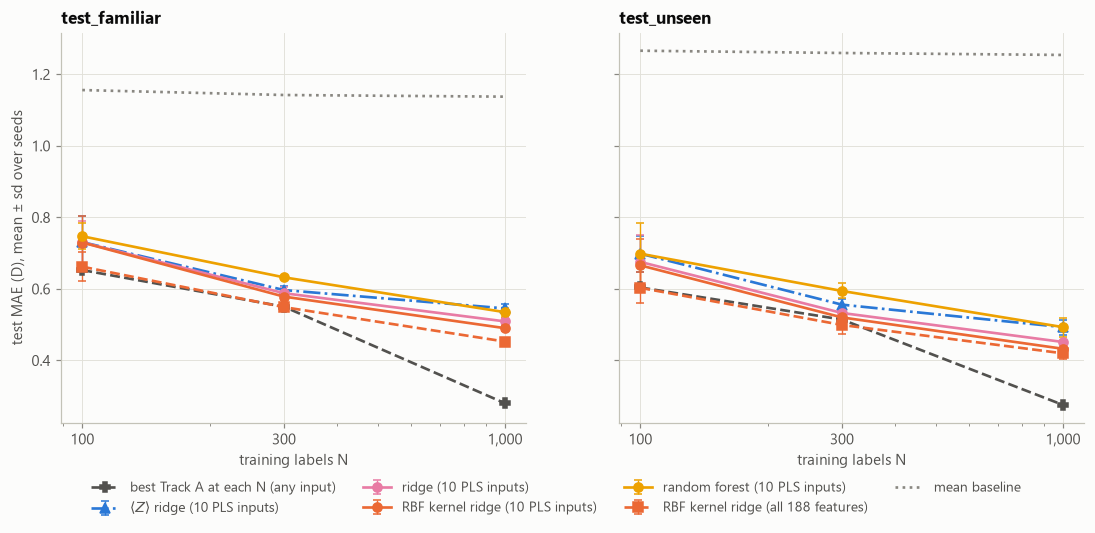

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, ev in zip(axes, TEST):
    for model, inputs in COMPARE:
        s = per_seed(model, inputs, ev).groupby("n_train").agg(["mean", "std"])
        style = model_style(model)
        if inputs == "all_legal":
            style.update(linestyle="--", marker="s")
        if model == "mean":
            style = {"color": MUTED, "linestyle": ":", "marker": None}
        ax.errorbar(s.index, s["mean"], yerr=None if model == "mean" else s["std"], capsize=2.5, elinewidth=0.9,
                    label=f"{PLOT_NAME[model]} ({INPUTS[inputs]})" if model != "mean" else "mean baseline", **style)
    best = [track_a[(track_a["model"] == BEST_A[n]) & (track_a["eval_set"] == ev) & (track_a["n_train"] == n)]["mae_D"].mean()
            for n in SIZES]
    ax.plot(SIZES, best, color=INK_SECONDARY, linestyle="--", marker="P", label="best Track A at each N (any input)")
    ax.set(xscale="log", xlabel="training labels N", title=ev, xticks=SIZES)
    ax.set_xticklabels([f"{n:,}" for n in SIZES])
    ax.xaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel("test MAE (D), mean ± sd over seeds")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.1))
fig.savefig(figure_file("nb11_qridge_learning_curves.png"))
plt.show()

## 4. Finite shots

On a device each ⟨Z⟩ is estimated from S measurements ("shots"), with standard error √((1 − ⟨Z⟩²)/S). Here every
⟨Z⟩ of every training and test molecule is drawn as a device would return it, and the ridge readout is refit on the
noisy training features (5 repetitions per seed, at the settings chosen above). These are the small quantum test
subsets (80 familiar and 370 unseen molecules), so compare shots with "exact" on the same subsets.

In [8]:
shots = pd.read_csv(results_file("test_run01_shots.csv"))
s = shots[shots["model"] == "qridge"].groupby(["eval_set", "n_train", "shots"])["mae_D"].mean().unstack("shots")
s = s[[np.inf, 10000.0, 1000.0, 100.0]]
s.columns = ["exact", "10,000 shots", "1,000 shots", "100 shots"]
display(s.style.format("{:.3f}").set_caption("MAE (D) on the quantum test subsets, mean over seeds × 5 repetitions"))

## 5. Simulated device noise and IBM hardware

Trained on S_(0, 100) and scored on 60 test molecules (30 per quantum subset), at 1,000 shots per circuit: exact
simulation; an ideal device (shots only); two noise models built from IBM calibration data (`FakeFez`, IBM Heron r2,
and `FakeQuebec`, for `ibm_quebec`), simulated on Qiskit Aer after transpiling the circuits for the device; and the
real `ibm_quebec` (job `db3da0kvf2bc73csuk60`: 160 circuits × 1,000 shots, 45 s of charged QPU time). In every case
the ridge readout is refit on the measured training features.

In [9]:
noise = pd.read_csv(results_file("test_run01_noise.csv"))
fez = noise[noise["model"] == "qridge"].set_index("mode")["mae_D"]
ibm = pd.read_csv(results_file("hardware_ibm_quebec_20261007-1925_scores.csv"))
quebec = pd.read_csv(results_file("hardware_FakeQuebec_20261007-2019_scores.csv"))


def both(frame, mode):
    return frame[(frame["model"] == "qridge") & (frame["mode"] == mode) & (frame["test_subset"] == "both")]["mae_D"].item()


row = {"exact": fez["exact"], "ideal device, 1,000 shots": fez["shots only"], "FakeFez noise model": fez["noisy"],
       "FakeQuebec noise model": both(quebec, "FakeQuebec noise model (local Aer)"), "IBM ibm_quebec": both(ibm, "ibm_quebec")}
display(pd.DataFrame([row], index=["MAE (D), 60 test molecules"]).style.format("{:.3f}"))
per = ibm[ibm["model"] == "qridge"].pivot(index="mode", columns="test_subset", values="mae_D")
display(per.style.format("{:.3f}").set_caption("the hardware job by test subset (its ideal-device shots are a separate draw)"))

,exact,"ideal device, 1,000 shots",FakeFez noise model,FakeQuebec noise model,IBM ibm_quebec
"MAE (D), 60 test molecules",0.794,0.817,0.812,0.798,0.778


test_subset,both,test_familiar_q,test_unseen_q
mode,,,
exact,0.794,0.784,0.804
ibm_quebec,0.778,0.792,0.764
"ideal device, 1,000 shots",0.806,0.822,0.790


## 6. What a full run would cost

Circuits and a lower bound on QPU time (circuits × shots × (circuit duration + readout + repetition delay), no queue
or job overhead) at 1,000 shots per circuit, to train on N molecules and predict the 9,183 development molecules,
from notebook 09. The ⟨Z⟩ ridge needs one circuit per molecule; the fidelity kernel needs one per pair. For scale,
IBM's free Open Plan provides 10 minutes per 28 days.

In [10]:
costs = pd.read_csv(results_file("nb09_model_costs.csv"))
display(costs[costs["N"] == 1000].drop(columns="N").set_index("model").style.format({
    "circuits to train": "{:,}", "circuits to predict 9,183 molecules": "{:,}", "QPU hours to train": "{:.2f}",
    "QPU hours to predict": "{:.2f}", "Open Plan months (train + predict)": "{:,.0f}"}).set_caption("N = 1,000"))

,circuits to train,"circuits to predict 9,183 molecules",QPU hours to train,QPU hours to predict,Open Plan months (train + predict)
model,,,,,
quantum kernel ridge (ZZ map),"499,500","9,183,000",35.90,659.95,"4,175"
projected quantum kernel,"3,000","27,549",0.21,1.96,13
quantum-feature ridge (team model),"1,000","9,183",0.07,0.65,4


## What we learned

1. **The circuit computes a classical formula.** Each ⟨Z⟩ feature has an exact closed form (matching Qiskit's
   simulation to ~10⁻¹⁵), so the model is ridge regression on a fixed classical feature map.
2. **At the settings cross-validation chose, that map is almost linear.** Every seed chose the smallest angle scale
   at N = 1,000 (γ = 0.020), where a linear function of the inputs explains 99% of the features' variance. The
   nonlinear regime exists at larger γ, but it predicts worse.
3. **It is slightly weaker than plain ridge on the same inputs.** Test MAE 0.731 / 0.597 / 0.545 D on familiar
   formulas at N = 100 / 300 / 1,000 (0.493 D on unseen formulas at 1,000). Paired with plain ridge on the same
   training sets and molecules, it is +0.001 ± 0.012, +0.009 ± 0.006 and +0.036 ± 0.011 D worse; against RBF kernel
   ridge, +0.055 ± 0.008 D at 1,000. Its larger tuning budget (165 settings against 15 for plain ridge) does not
   help. The best classical model at N = 1,000 (the latent-charge network) reaches 0.280 D.
4. **It is robust to shots and noise.** At 1,000 shots per circuit its error on the quantum test subsets rises by
   0.015 / 0.021 D (0.625 → 0.640 and 0.749 → 0.770 D at N = 1,000); simulated device noise changes it by less than
   0.02 D.
5. **It ran on real hardware as well as in simulation.** On `ibm_quebec`: 0.778 D on 60 test molecules, against
   0.794 D exact. With 60 molecules each MAE is uncertain by about ±0.1 D, so this means "as good as simulation".
   Refitting the readout on the device's own measurements absorbs the device's systematic bias.
6. **It is the cheapest quantum model to run.** One circuit per molecule: about 0.7 QPU-hours to train on 1,000
   molecules and predict 9,183, against about 700 for the fidelity kernel.

**Not shown for this model:** the end-to-end rotation/translation/relabelling test and the composition-only
ablation were run for the quantum kernel models (notebook 08); the ⟨Z⟩ ridge uses the same invariant inputs, but its
own end-to-end check and ablation have not been run.

**Back to:** the [README](../README.md) for the whole project, or [notebook 10](10_test_set_results.ipynb) for every
model on the test sets.